Dataset Shape: (420, 10)
Features: ['Rainfall_mm', 'Temperature_C', 'Evaporation_mm', 'Humidity_Proxy_C', 'Wind_Speed_mps', 'Vegetation_Percentage', 'Slope_degrees', 'Soil_Type_USDA_Code', 'GWL_lag_1', 'GWL_lag_2', 'GWL_lag_3', 'GWL_lag_6', 'GWL_lag_12', 'GWL_roll_mean_3', 'Rainfall_sum_3', 'GWL_roll_mean_6', 'Rainfall_sum_6', 'GWL_roll_mean_12', 'Rainfall_sum_12', 'Month_sin', 'Month_cos', 'Time_Index']
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000097 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1893
[LightGBM] [Info] Number of data points in the train set: 326, number of used features: 20
[LightGBM] [Info] Start training from score 1.654417
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits

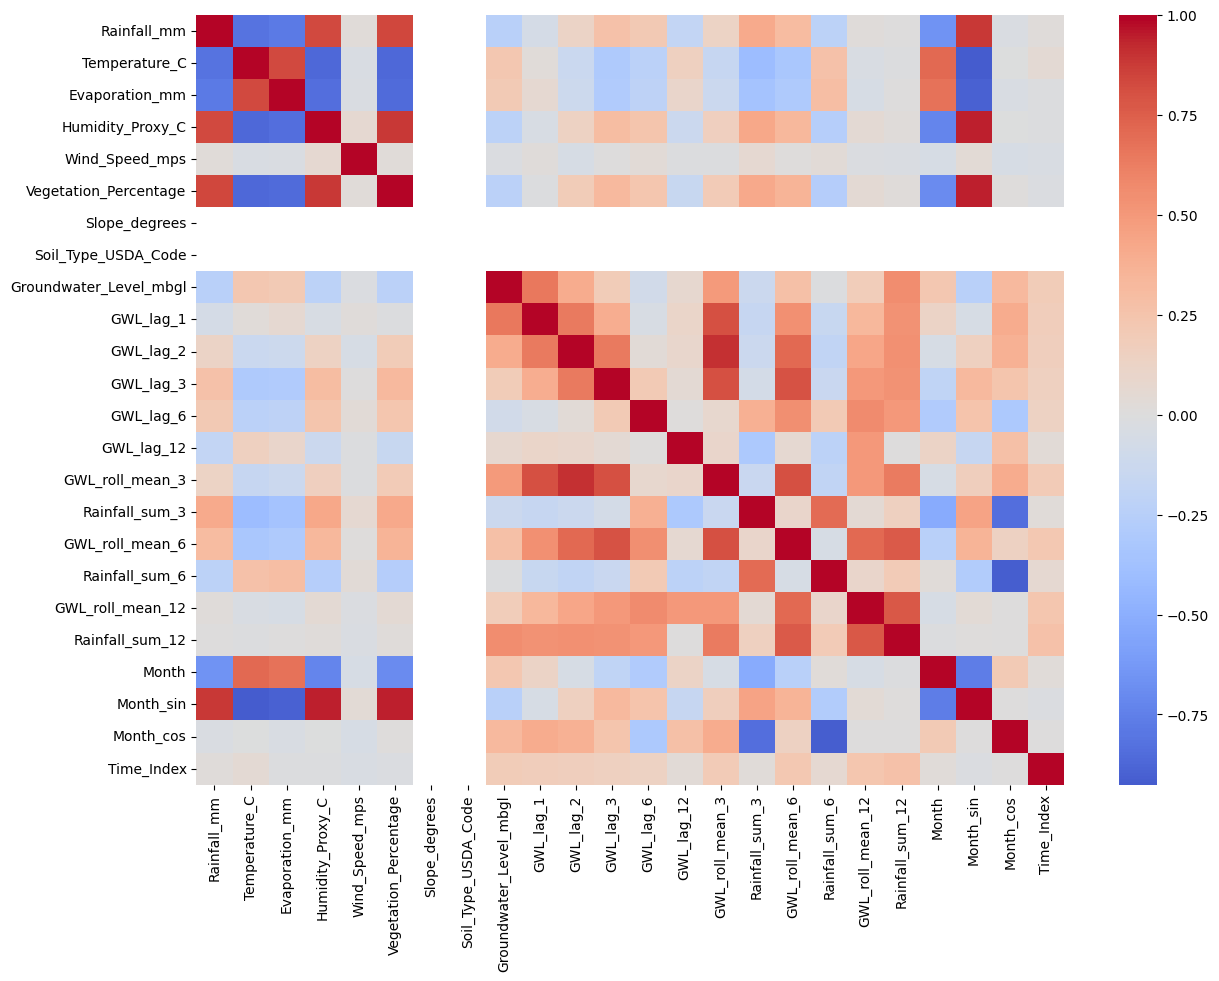

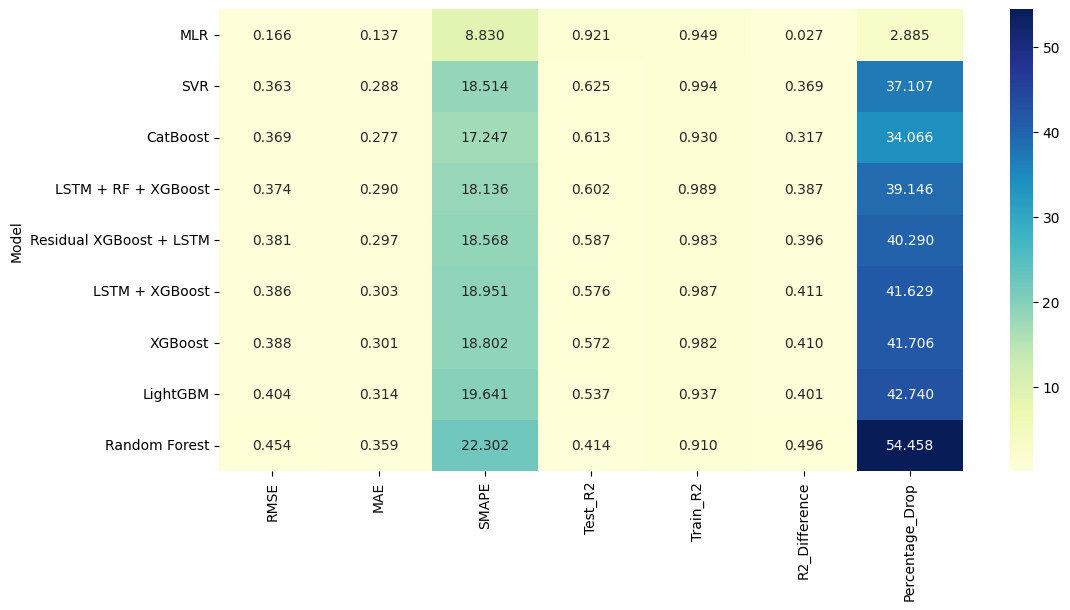

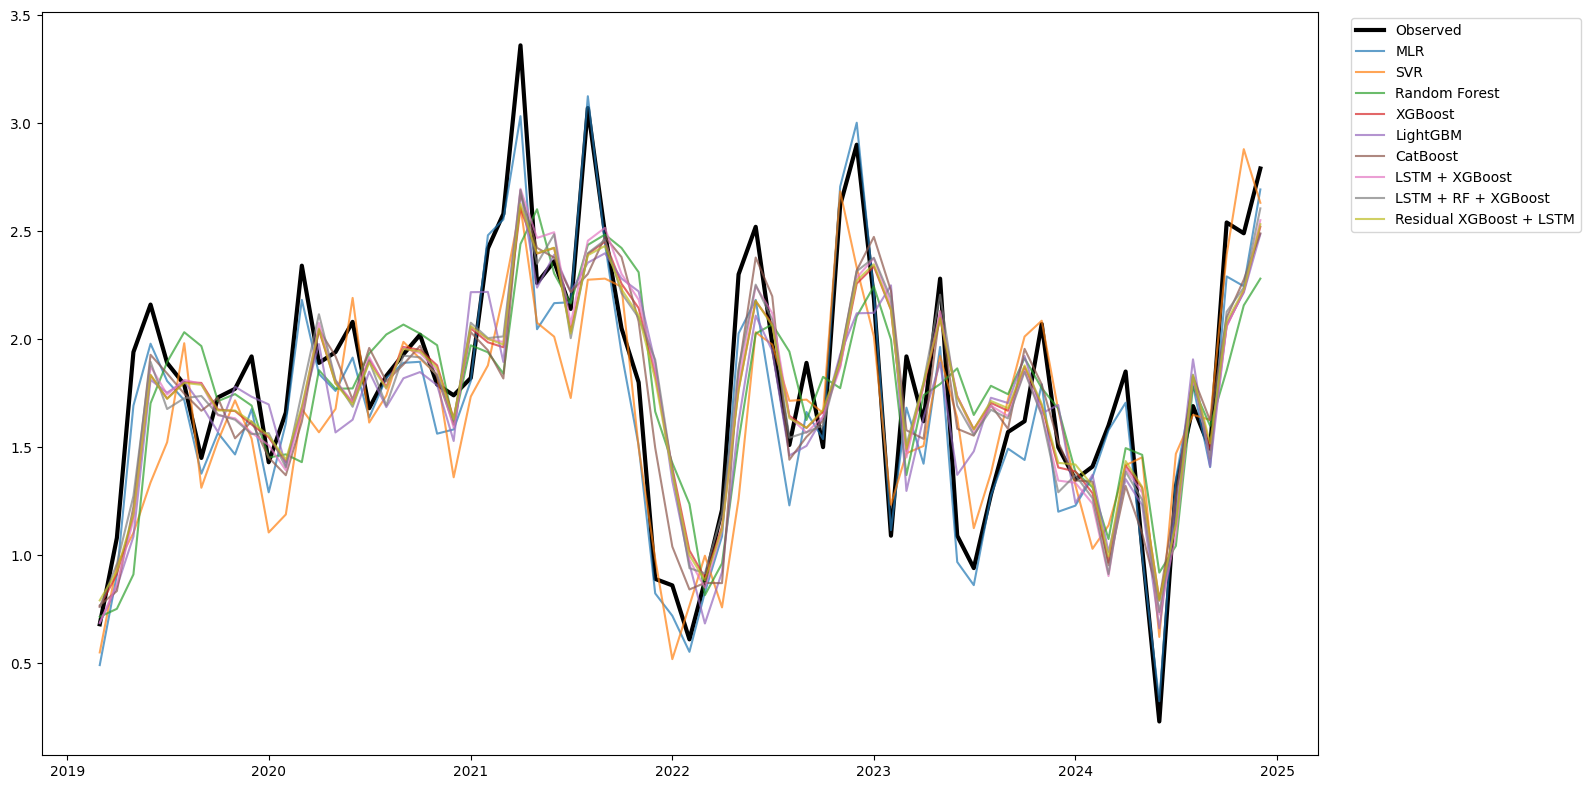

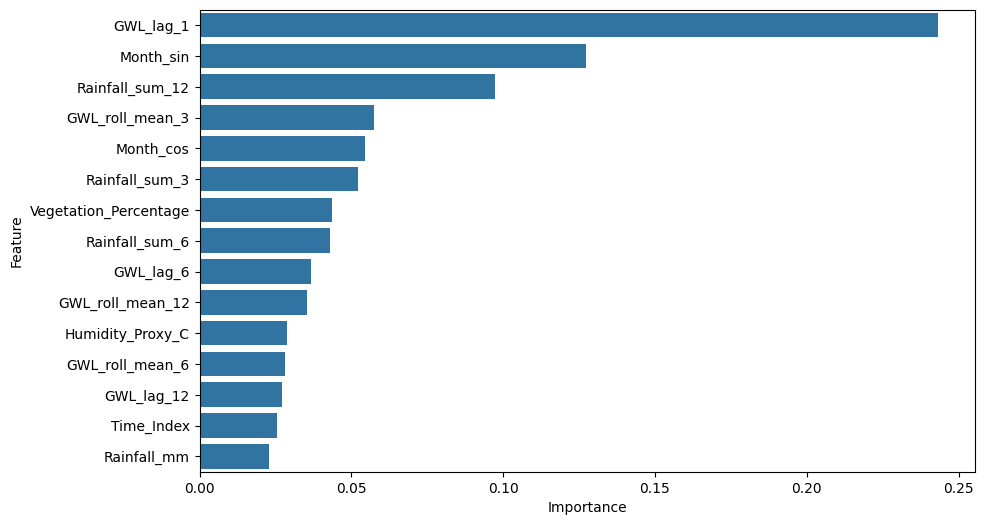

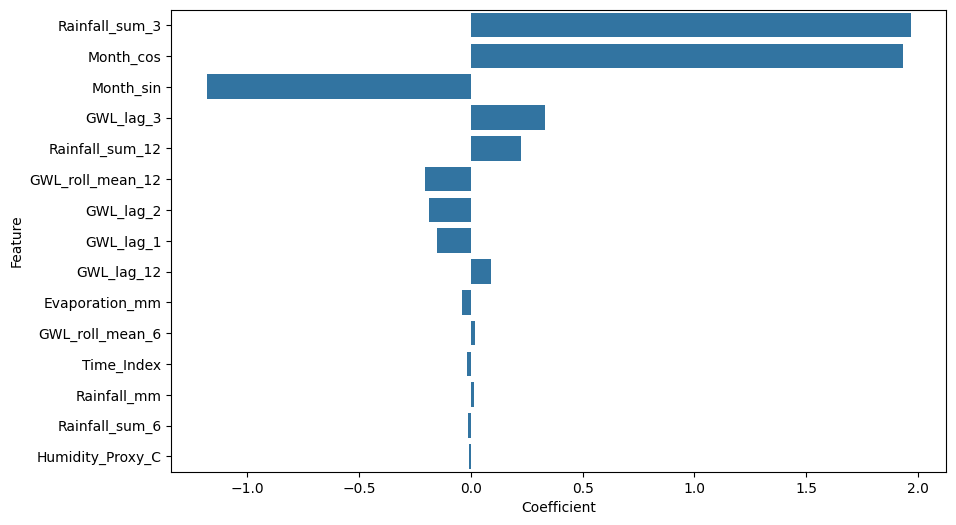

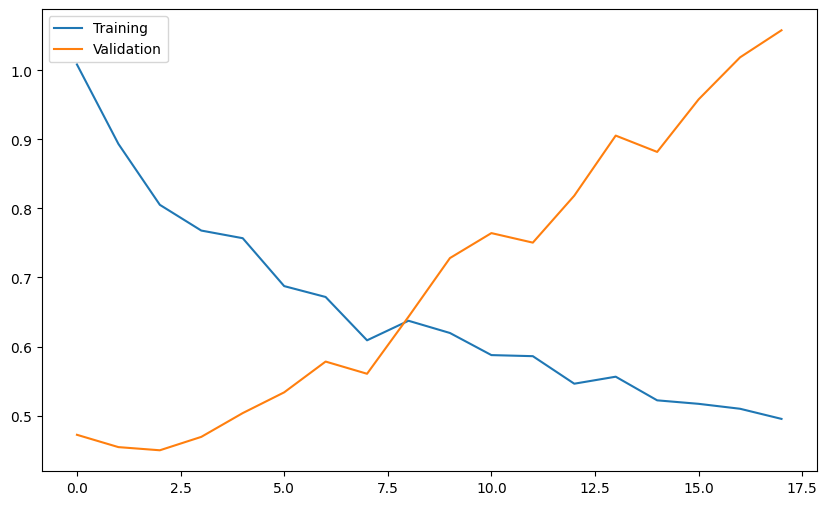

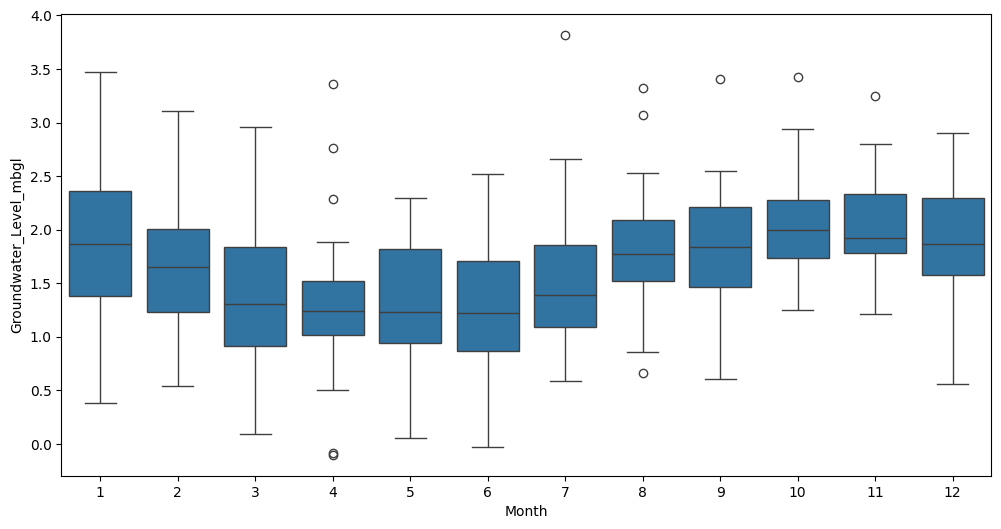

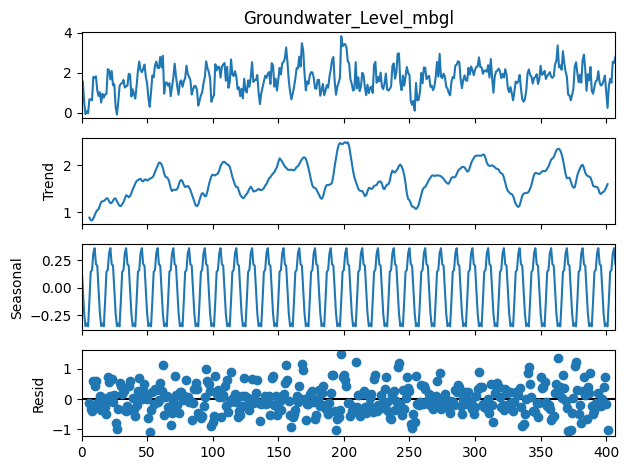

Saved: Groundwater_Results.xlsx


In [5]:
# ==========================================================
# INSTALL PACKAGES
# ==========================================================

!pip install -q tensorflow xgboost lightgbm catboost openpyxl statsmodels seaborn

# ==========================================================
# IMPORT LIBRARIES
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from scipy import stats

# ==========================================================
# SETTINGS
# ==========================================================

np.random.seed(42)
tf.random.set_seed(42)

FILE_PATH = "/content/CHENNAI_Groundwater.xlsx"

TIME_COL = "Time"
TARGET = "Groundwater_Level_mbgl"
LOOKBACK = 12

# ==========================================================
# LOAD DATA
# ==========================================================

df = pd.read_excel(FILE_PATH)

df[TIME_COL] = pd.to_datetime(df[TIME_COL])

df = df.sort_values(TIME_COL).reset_index(drop=True)

print("Dataset Shape:", df.shape)

# ==========================================================
# FEATURE ENGINEERING
# ==========================================================

for lag in [1, 2, 3, 6, 12]:

    df[f"GWL_lag_{lag}"] = df[TARGET].shift(lag)

for window in [3, 6, 12]:

    df[f"GWL_roll_mean_{window}"] = (
        df[TARGET]
        .shift(1)
        .rolling(window)
        .mean()
    )

    if "Rainfall_mm" in df.columns:

        df[f"Rainfall_sum_{window}"] = (
            df["Rainfall_mm"]
            .shift(1)
            .rolling(window)
            .sum()
        )

df["Month"] = df[TIME_COL].dt.month

df["Month_sin"] = np.sin(
    2 * np.pi * df["Month"] / 12
)

df["Month_cos"] = np.cos(
    2 * np.pi * df["Month"] / 12
)

df["Time_Index"] = np.arange(len(df))

df = df.dropna().reset_index(drop=True)

# ==========================================================
# FEATURES
# ==========================================================

exclude = [TIME_COL, TARGET, "Month"]

features = [
    col for col in df.columns
    if col not in exclude
]

X = df[features]
y = df[TARGET]

print("Features:", features)

# ==========================================================
# TRAIN TEST SPLIT
# ==========================================================

split = int(len(df) * 0.80)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

time_test = df[TIME_COL].iloc[split:]

# ==========================================================
# SCALING FOR LSTM
# ==========================================================

feature_scaler = StandardScaler()
target_scaler = StandardScaler()

X_train_scaled = feature_scaler.fit_transform(X_train)
X_test_scaled = feature_scaler.transform(X_test)

y_train_scaled = target_scaler.fit_transform(
    y_train.values.reshape(-1, 1)
)

def create_sequences(X, y, lookback):

    Xs, ys = [], []

    for i in range(lookback, len(X)):

        Xs.append(X[i-lookback:i])
        ys.append(y[i])

    return np.array(Xs), np.array(ys)

X_train_lstm, y_train_lstm = create_sequences(
    X_train_scaled,
    y_train_scaled,
    LOOKBACK
)

X_test_lstm, _ = create_sequences(
    X_test_scaled,
    np.zeros((len(X_test_scaled), 1)),
    LOOKBACK
)

y_train_actual = y_train.iloc[LOOKBACK:].values
y_test_actual = y_test.iloc[LOOKBACK:].values

time_test_actual = time_test.iloc[LOOKBACK:]

# ==========================================================
# MODELS
# ==========================================================

mlr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

svr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVR(
        kernel="rbf",
        C=10,
        epsilon=0.05
    ))
])

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

lgbm_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=4,
    random_state=42
)

cat_model = CatBoostRegressor(
    iterations=500,
    depth=4,
    learning_rate=0.03,
    verbose=0,
    random_state=42
)

# ==========================================================
# TRAIN
# ==========================================================

mlr_model.fit(X_train, y_train)
svr_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)
lgbm_model.fit(X_train, y_train)
cat_model.fit(X_train, y_train)

# ==========================================================
# PREDICTIONS
# ==========================================================

pred_mlr = mlr_model.predict(X_test.iloc[LOOKBACK:])
pred_svr = svr_model.predict(X_test.iloc[LOOKBACK:])
pred_rf = rf_model.predict(X_test.iloc[LOOKBACK:])
pred_xgb = xgb_model.predict(X_test.iloc[LOOKBACK:])
pred_lgbm = lgbm_model.predict(X_test.iloc[LOOKBACK:])
pred_cat = cat_model.predict(X_test.iloc[LOOKBACK:])

# ==========================================================
# LSTM
# ==========================================================

lstm_model = Sequential([

    LSTM(
        32,
        return_sequences=True,
        input_shape=(
            X_train_lstm.shape[1],
            X_train_lstm.shape[2]
        )
    ),

    Dropout(0.4),

    LSTM(16),

    Dropout(0.4),

    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

lstm_train_pred = target_scaler.inverse_transform(
    lstm_model.predict(X_train_lstm, verbose=0)
).flatten()

lstm_test_pred = target_scaler.inverse_transform(
    lstm_model.predict(X_test_lstm, verbose=0)
).flatten()

# ==========================================================
# HYBRID MODELS
# ==========================================================

xgb_train_pred = xgb_model.predict(
    X_train.iloc[LOOKBACK:]
)

rf_train_pred = rf_model.predict(
    X_train.iloc[LOOKBACK:]
)

meta_1 = LinearRegression()

meta_1.fit(
    np.column_stack([
        lstm_train_pred,
        xgb_train_pred
    ]),
    y_train_actual
)

pred_lstm_xgb = meta_1.predict(
    np.column_stack([
        lstm_test_pred,
        pred_xgb
    ])
)

meta_2 = LinearRegression()

meta_2.fit(
    np.column_stack([
        lstm_train_pred,
        rf_train_pred,
        xgb_train_pred
    ]),
    y_train_actual
)

pred_lstm_rf_xgb = meta_2.predict(
    np.column_stack([
        lstm_test_pred,
        pred_rf,
        pred_xgb
    ])
)

residuals_train = y_train_actual - xgb_train_pred

residual_scaler = StandardScaler()

residual_scaled = residual_scaler.fit_transform(
    residuals_train.reshape(-1,1)
)

res_lstm = Sequential([
    LSTM(32, input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])),
    Dropout(0.4),
    Dense(1)
])

res_lstm.compile(
    optimizer="adam",
    loss="mse"
)

res_lstm.fit(
    X_train_lstm,
    residual_scaled,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

residual_pred = residual_scaler.inverse_transform(
    res_lstm.predict(X_test_lstm, verbose=0)
).flatten()

pred_residual = pred_xgb + residual_pred

# ==========================================================
# RESULTS
# ==========================================================

all_predictions = {

    "MLR": pred_mlr,
    "SVR": pred_svr,
    "Random Forest": pred_rf,
    "XGBoost": pred_xgb,
    "LightGBM": pred_lgbm,
    "CatBoost": pred_cat,
    "LSTM + XGBoost": pred_lstm_xgb,
    "LSTM + RF + XGBoost": pred_lstm_rf_xgb,
    "Residual XGBoost + LSTM": pred_residual
}

train_predictions = {

    "MLR": mlr_model.predict(X_train.iloc[LOOKBACK:]),
    "SVR": svr_model.predict(X_train.iloc[LOOKBACK:]),
    "Random Forest": rf_train_pred,
    "XGBoost": xgb_train_pred,
    "LightGBM": lgbm_model.predict(X_train.iloc[LOOKBACK:]),
    "CatBoost": cat_model.predict(X_train.iloc[LOOKBACK:]),

    "LSTM + XGBoost":
        meta_1.predict(
            np.column_stack([
                lstm_train_pred,
                xgb_train_pred
            ])
        ),

    "LSTM + RF + XGBoost":
        meta_2.predict(
            np.column_stack([
                lstm_train_pred,
                rf_train_pred,
                xgb_train_pred
            ])
        ),

    "Residual XGBoost + LSTM":
        xgb_train_pred +
        residual_scaler.inverse_transform(
            res_lstm.predict(
                X_train_lstm,
                verbose=0
            )
        ).flatten()
}

def smape(y_true, y_pred):

    return np.mean(
        2*np.abs(y_pred-y_true)/
        (np.abs(y_true)+np.abs(y_pred))
    )*100

results = []

n = len(y_test_actual)
p = len(features)

for model in all_predictions:

    train_r2 = r2_score(
        y_train_actual,
        train_predictions[model]
    )

    test_r2 = r2_score(
        y_test_actual,
        all_predictions[model]
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_actual,
            all_predictions[model]
        )
    )

    mae = mean_absolute_error(
        y_test_actual,
        all_predictions[model]
    )

    results.append([

        model,

        rmse,

        mae,

        smape(
            y_test_actual,
            all_predictions[model]
        ),

        test_r2,

        train_r2,

        train_r2 - test_r2,

        ((train_r2 - test_r2)/train_r2)*100
    ])

results_df = pd.DataFrame(

    results,

    columns=[
        "Model",
        "RMSE",
        "MAE",
        "SMAPE",
        "Test_R2",
        "Train_R2",
        "R2_Difference",
        "Percentage_Drop"
    ]
)

results_df = results_df.sort_values(
    "Test_R2",
    ascending=False
)

print(results_df.round(4))

# ==========================================================
# CORRELATION HEATMAP
# ==========================================================

plt.figure(figsize=(14,10))

sns.heatmap(
    df.drop(columns=TIME_COL).corr(),
    cmap="coolwarm",
    center=0
)

plt.show()

# ==========================================================
# PERFORMANCE HEATMAP
# ==========================================================

plt.figure(figsize=(12,6))

sns.heatmap(
    results_df.set_index("Model"),
    annot=True,
    cmap="YlGnBu",
    fmt=".3f"
)

plt.show()

# ==========================================================
# OBSERVED VS PREDICTED
# ==========================================================

plt.figure(figsize=(16,8))

plt.plot(
    time_test_actual,
    y_test_actual,
    label="Observed",
    color="black",
    linewidth=3
)

for name, pred in all_predictions.items():

    plt.plot(
        time_test_actual,
        pred,
        label=name,
        alpha=0.7
    )

plt.legend(
    bbox_to_anchor=(1.02,1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

# ==========================================================
# FEATURE IMPORTANCE
# ==========================================================

importance_df = pd.DataFrame({

    "Feature": features,

    "Importance": xgb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.show()

# ==========================================================
# MLR COEFFICIENTS
# ==========================================================

coef_df = pd.DataFrame({

    "Feature": features,

    "Coefficient":
        mlr_model.named_steps["model"].coef_
})

coef_df = coef_df.sort_values(
    "Coefficient",
    key=abs,
    ascending=False
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=coef_df.head(15),
    x="Coefficient",
    y="Feature"
)

plt.show()

# ==========================================================
# LSTM LOSS
# ==========================================================

plt.figure(figsize=(10,6))

plt.plot(history.history["loss"])

plt.plot(history.history["val_loss"])

plt.legend([
    "Training",
    "Validation"
])

plt.show()

# ==========================================================
# MONTHLY BOXPLOT
# ==========================================================

plt.figure(figsize=(12,6))

sns.boxplot(
    data=df,
    x="Month",
    y=TARGET
)

plt.show()

# ==========================================================
# SEASONAL DECOMPOSITION
# ==========================================================

decomp = seasonal_decompose(
    df[TARGET],
    period=12,
    model="additive"
)

decomp.plot()

plt.show()

# ==========================================================
# SAVE RESULTS
# ==========================================================

prediction_df = pd.DataFrame({

    "Time": time_test_actual,

    "Observed": y_test_actual,

    **all_predictions
})

with pd.ExcelWriter(
    "Groundwater_Results.xlsx"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="Performance",
        index=False
    )

    prediction_df.to_excel(
        writer,
        sheet_name="Predictions",
        index=False
    )

print("Saved: Groundwater_Results.xlsx")
